# Back-translation NLLB + LoRA — renforcer en↔ewe / fr↔ewe

**Projet GR02** · Notebook **dédié** à l'itération back-translation.

Ce notebook **ne modifie pas** `01_pipeline_nllb_lora.ipynb` ni le modèle de base.
Il entraîne un nouvel adaptateur dans un dossier **séparé** (`models/nllb-ewe-lora-bt`)
sur le train **augmenté** (`nllb_train_aug.csv` = train propre + paires synthétiques),
puis **compare** ses scores au modèle de base.

Pipeline : génération du CSV augmenté (section 2) → entraînement BT → évaluation → comparaison base vs BT → on garde le meilleur.

## 0. Prérequis

1. Le **modèle de base** doit déjà exister (`models/nllb-ewe-lora`) : c'est lui qui
   génère la back-translation.
2. Sa **sauvegarde** doit exister (`models/nllb-ewe-lora-clean-2ep`) pour la comparaison.
   Sinon : `Get-ChildItem models/nllb-ewe-lora -File | Copy-Item -Destination models/nllb-ewe-lora-clean-2ep` (créer le dossier d'abord).
3. `matplotlib` installé : `.venv\Scripts\python.exe -m pip install matplotlib`.

In [1]:
from pathlib import Path
import os
import sys
import time

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "nllb"
TRAIN_CSV = DATA_DIR / "nllb_train_aug.csv"
VALID_CSV = DATA_DIR / "nllb_valid.csv"
TEST_CSV = DATA_DIR / "nllb_test.csv"

MODEL_NAME = "facebook/nllb-200-distilled-600M"
OUTPUT_DIR = PROJECT_ROOT / "models" / "nllb-ewe-lora-bt"
BASELINE_DIR = PROJECT_ROOT / "models" / "nllb-ewe-lora-clean-2ep"

MODE = "full"
REQUIRE_CUDA = True
RUN_BACKTRANSLATION = False

IS_SMOKE = MODE == "smoke"
MAX_TRAIN_SAMPLES = 512 if IS_SMOKE else 300000
MAX_VALID_SAMPLES = 128 if IS_SMOKE else 6000
MAX_EVAL_PER_DIRECTION = 20 if IS_SMOKE else 200
EPOCHS = 0.05 if IS_SMOKE else 2.0
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 2
MAX_SOURCE_LENGTH = 128
MAX_TARGET_LENGTH = 128
LEARNING_RATE = 2e-4
BT_SAMPLE_A = 60000
BT_SAMPLE_B = 60000

print("Train (augmenté):", TRAIN_CSV.name, "| échantillon:", MAX_TRAIN_SAMPLES)
print("Sortie LoRA (BT):", OUTPUT_DIR)
print("Baseline (comparaison):", BASELINE_DIR)

Train (augmente): nllb_train_aug.csv | echantillon: 300000
Sortie LoRA (BT): D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora-bt
Baseline (comparaison): D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora-clean-2ep


## 1. Diagnostic GPU

In [2]:
import torch

print("torch:", torch.__version__)
print("cuda_available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device_name:", torch.cuda.get_device_name(0))
    print("bf16_supported:", torch.cuda.is_bf16_supported())
    torch.set_float32_matmul_precision("high")
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

if REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError("CUDA indisponible. Installez PyTorch CUDA avant l'entraînement.")

torch: 2.11.0+cu130
cuda_available: True
device_name: NVIDIA GeForce RTX 5080 Laptop GPU
bf16_supported: True


## 2. Génération des données augmentées (back-translation)

On **garde l'éwé humain en cible** (qualité garantie) et on fabrique une **source synthétique** avec le modèle déjà entraîné (`models/nllb-ewe-lora`). On part uniquement des paires propres `(ewe, fr)` du **split train** (aucune fuite valid/test), en ne conservant que des cibles éwé **pristines** : cosinus ≥ 0.65 et présence de vrais caractères éwé.

Trois jeux de paires synthétiques sont produits :

- **A — `fr → en`** : crée `en_synth → ewe_humain` (enrichit **en→ewe**, contenu varié non-biblique).
- **A2 — réutilise le même `en_synth`** : crée `ewe_humain → en_synth` (équilibre **ewe→en**, sans appel GPU supplémentaire ; l'anglais vient de `fr→en`, la direction la plus fiable).
- **B — `ewe → fr`** : crée `fr_synth → ewe_humain` (renforce **fr→ewe** et réduit l'off-target).

Le résultat (`nllb_train_aug.csv` = train original + paires synthétiques) sert à ré-entraîner un modèle **dans un dossier séparé** (`nllb-ewe-lora-bt`). Le test et le valid ne sont **pas** modifiés.

Mettez `RUN_BACKTRANSLATION = True` dans la cellule de configuration pour lancer la génération — c'est **long et sur GPU**. Si `nllb_train_aug.csv` existe déjà, laissez `False`.

In [3]:
import hashlib
import pandas as pd
from peft import PeftModel
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

ADAPTER = str(PROJECT_ROOT / "models" / "nllb-ewe-lora")
BT_INPUT_CSV = DATA_DIR / "nllb_train.csv"
NLLB = {"fra": "fra_Latn", "eng": "eng_Latn", "ewe": "ewe_Latn"}
BT_MIN_QUALITY = 0.65
BT_BATCH_SIZE = 48
BT_NUM_BEAMS = 4

def _sid(*parts):
    return hashlib.sha1("␟".join(str(p) for p in parts).encode("utf-8")).hexdigest()

if RUN_BACKTRANSLATION:
    bt_device = "cuda" if torch.cuda.is_available() else "cpu"
    bt_tok = AutoTokenizer.from_pretrained(ADAPTER)
    bt_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    bt_model = PeftModel.from_pretrained(bt_model, ADAPTER).to(bt_device).eval()
    try:
        bt_model.generation_config.max_length = None
    except Exception:
        pass
    bt_bf16 = bt_device == "cuda" and torch.cuda.is_bf16_supported()

    @torch.no_grad()
    def bt_translate(texts, src, tgt):
        bt_tok.src_lang = NLLB[src]
        bos = bt_tok.convert_tokens_to_ids(NLLB[tgt])
        out = []
        ctx = torch.autocast("cuda", dtype=torch.bfloat16) if bt_bf16 else torch.autocast("cpu", enabled=False)
        for i in range(0, len(texts), BT_BATCH_SIZE):
            batch = [str(x) for x in texts[i:i + BT_BATCH_SIZE]]
            enc = bt_tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(bt_device)
            with ctx:
                gen = bt_model.generate(**enc, forced_bos_token_id=bos, max_new_tokens=128, num_beams=BT_NUM_BEAMS)
            out.extend(bt_tok.batch_decode(gen, skip_special_tokens=True))
            if (i // BT_BATCH_SIZE) % 50 == 0:
                print(f"  {src}->{tgt}: {min(i + BT_BATCH_SIZE, len(texts))}/{len(texts)}", flush=True)
        return out

    train = pd.read_csv(BT_INPUT_CSV)
    pool = train[(train.src_lang == "ewe") & (train.tgt_lang == "fra")][["src_text", "tgt_text", "quality_score"]].copy()
    pool.columns = ["ewe", "fr", "cos"]
    pool = pool.dropna().drop_duplicates(subset=["ewe", "fr"]).reset_index(drop=True)
    ewe_chars = set("ɖƒŋɔɛɣʋ̃")
    has_ewe = pool["ewe"].map(lambda s: any(c in ewe_chars for c in str(s)))
    pool = pool[(pool["cos"].astype(float) >= BT_MIN_QUALITY) & has_ewe].reset_index(drop=True)
    print(f"Pool ewe-fr propre (train, cos>={BT_MIN_QUALITY} + caractères éwé): {len(pool)} paires")

    new_rows = []

    def bt_emit(src_lang, tgt_lang, src_texts, ewe_targets, source_tag):
        for s, e in zip(src_texts, ewe_targets):
            s, e = str(s).strip(), str(e).strip()
            if not s or not e:
                continue
            new_rows.append({
                "id": _sid("train", src_lang, tgt_lang, s, e),
                "split": "train",
                "src_lang": src_lang, "tgt_lang": tgt_lang,
                "src_lang_nllb": NLLB[src_lang], "tgt_lang_nllb": NLLB[tgt_lang],
                "src_text": s, "tgt_text": e,
                "source": source_tag, "domain": "synthetic",
                "quality_score": 1.0, "is_religious": False, "license": "",
            })

    if BT_SAMPLE_A > 0:
        a = pool.sample(n=min(BT_SAMPLE_A, len(pool)), random_state=1)
        print(f"[A] fr->en sur {len(a)} paires (crée en->ewe)")
        en_synth = bt_translate(a["fr"].tolist(), "fra", "eng")
        bt_emit("eng", "ewe", en_synth, a["ewe"].tolist(), "synthetic:bt:fr2en")
        print(f"[A2] réutilise en_synth pour créer ewe->en ({len(a)} paires)")
        bt_emit("ewe", "eng", a["ewe"].tolist(), en_synth, "synthetic:pivot:fr2en")

    if BT_SAMPLE_B > 0:
        b = pool.sample(n=min(BT_SAMPLE_B, len(pool)), random_state=2)
        print(f"[B] ewe->fr sur {len(b)} paires (crée fr->ewe)")
        fr_synth = bt_translate(b["ewe"].tolist(), "ewe", "fra")
        bt_emit("fra", "ewe", fr_synth, b["ewe"].tolist(), "synthetic:bt:ewe2fr")

    aug = pd.DataFrame(new_rows)
    out_df = pd.concat([train, aug], ignore_index=True)
    TRAIN_CSV.parent.mkdir(parents=True, exist_ok=True)
    out_df.to_csv(TRAIN_CSV, index=False, encoding="utf-8")
    print(f"Train augmenté: {len(train)} + {len(aug)} = {len(out_df)} -> {TRAIN_CSV}")
    print(out_df.groupby(["src_lang", "tgt_lang"]).size().to_string())

    del bt_model, bt_tok
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    print("Génération ignorée. On utilise le fichier augmenté existant.")

if not TRAIN_CSV.exists():
    raise FileNotFoundError(
        f"{TRAIN_CSV} introuvable. Mets RUN_BACKTRANSLATION = True dans la configuration pour le générer."
    )
print("OK, train augmenté présent:", TRAIN_CSV)

Generation ignoree. On utilise le fichier existant.
OK, train augmente present: D:\python\traducteur-fr-en-ewe\data\processed\nllb\nllb_train_aug.csv


## 3. Chargement des données augmentées

On vérifie l'apport des paires synthétiques (surtout en→ewe, qui passe de ~5,6k à ~65k).

In [4]:
import pandas as pd

def read_training_csv(path, max_samples=None):
    df = pd.read_csv(path)
    df["src_text"] = df["src_text"].fillna("").astype(str).str.strip()
    df["tgt_text"] = df["tgt_text"].fillna("").astype(str).str.strip()
    df = df[(df["src_text"].str.len() > 0) & (df["tgt_text"].str.len() > 0)]
    if max_samples:
        df = df.sample(n=min(max_samples, len(df)), random_state=42)
    return df.reset_index(drop=True)

full_aug = pd.read_csv(TRAIN_CSV)
print("Train augmenté par direction (avant échantillonnage):")
print(full_aug.groupby(["src_lang", "tgt_lang"]).size().to_string())
if "domain" in full_aug.columns:
    print("Dont synthétique (domain == 'synthetic'):", int((full_aug["domain"] == "synthetic").sum()))

train_df = read_training_csv(TRAIN_CSV, MAX_TRAIN_SAMPLES)
valid_df = read_training_csv(VALID_CSV, MAX_VALID_SAMPLES)
print("train:", len(train_df), "valid:", len(valid_df))
display(train_df["src_lang"].str.cat(train_df["tgt_lang"], sep="->").value_counts())

Train augmente par direction (avant echantillonnage):
src_lang  tgt_lang
eng       ewe          78941
          fra         115227
ewe       eng          78926
          fra         115168
fra       eng         115166
          ewe         115306
Dont synthetique (domain == 'synthetic'): 146676
train: 300000 valid: 6000


src_lang
fra->ewe    56214
ewe->fra    55877
fra->eng    55700
eng->fra    55690
ewe->eng    38388
eng->ewe    38131
Name: count, dtype: int64

## 4. Modèle NLLB + LoRA (neuf)

On repart du modèle de BASE + un adaptateur LoRA neuf (entraînement from scratch sur
le train augmenté), pour une comparaison propre avec le modèle de base.

In [5]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments
from peft import LoraConfig, TaskType, get_peft_model

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
base_model.generation_config.max_length = None
if MODE == "full":
    base_model.gradient_checkpointing_enable()
    base_model.config.use_cache = False

lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"],
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

D:\python\traducteur-fr-en-ewe\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 512/512 [00:00<00:00, 21239.92it/s]


trainable params: 17,301,504 || all params: 632,375,296 || trainable%: 2.7360


## 5. Tokenisation

In [6]:
def preprocess(example):
    tokenizer.src_lang = example["src_lang_nllb"]
    tokenizer.tgt_lang = example["tgt_lang_nllb"]
    model_inputs = tokenizer(example["src_text"], max_length=MAX_SOURCE_LENGTH, truncation=True)
    labels = tokenizer(text_target=example["tgt_text"], max_length=MAX_TARGET_LENGTH, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

train_ds = Dataset.from_pandas(train_df, preserve_index=False).map(
    preprocess, remove_columns=train_df.columns.tolist(), desc="Tokenisation train")
valid_ds = Dataset.from_pandas(valid_df, preserve_index=False).map(
    preprocess, remove_columns=valid_df.columns.tolist(), desc="Tokenisation valid")

collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)
print(train_ds)
print(valid_ds)

Tokenisation valid: 100%|██████████| 6000/6000 [00:01<00:00, 4613.13 examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 300000
})
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 6000
})


## 6. Entraînement (dossier séparé `nllb-ewe-lora-bt`)

Entraînement NEUF (pas de `resume_from_checkpoint`). La sortie va dans un dossier séparé, donc le modèle de base n'est jamais touché.

> Sous Windows, on garde `dataloader_num_workers = 0` : avec une valeur supérieure, le multiprocessing « spawn » tente de pickler le collator puis le modèle, ce qui échoue avec le gradient checkpointing.

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
use_fp16 = torch.cuda.is_available() and not use_bf16

eval_steps = 25 if MODE == "smoke" else 1000
save_steps = 50 if MODE == "smoke" else 1000
logging_steps = 5 if MODE == "smoke" else 50

DATALOADER_WORKERS = 0

training_args = Seq2SeqTrainingArguments(
    output_dir=str(OUTPUT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    num_train_epochs=EPOCHS,
    warmup_ratio=0.03,
    fp16=use_fp16,
    bf16=use_bf16,
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=eval_steps,
    save_steps=save_steps,
    logging_steps=logging_steps,
    save_total_limit=3,
    predict_with_generate=False,
    report_to="none",
    dataloader_num_workers=DATALOADER_WORKERS,
    dataloader_pin_memory=True,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer,
    data_collator=collator,
)

start = time.time()
train_result = trainer.train()
elapsed = time.time() - start
trainer.save_model(str(OUTPUT_DIR))
tokenizer.save_pretrained(str(OUTPUT_DIR))
print("Temps d'entraînement (minutes) :", round(elapsed / 60, 2))
print("Adaptateur BT sauvegardé dans :", OUTPUT_DIR)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Step,Training Loss,Validation Loss
1000,2.851657,1.235840
2000,2.832097,1.223279
3000,2.727156,1.216836
4000,2.695782,1.211890
5000,2.696403,1.208386
6000,2.617289,1.203992
7000,2.693776,1.200126
8000,2.677788,1.198091
9000,2.580654,1.197425
9376,2.650432,1.197484


Temps entrainement minutes: 280.13
Adapter BT sauvegarde dans: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora-bt


## 7. Courbes d'entraînement

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
183,2.630250,0.566535,1.268969e-05,1.877227,8800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
184,2.581157,0.557413,1.159006e-05,1.887893,8850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
185,2.638125,0.564287,1.049043e-05,1.898560,8900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
186,2.658819,0.582938,9.390807e-06,1.909227,8950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
187,2.580654,0.518800,8.291181e-06,1.919893,9000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
188,NaN,NaN,NaN,1.919893,9000,1.197425,31.0052,193.516,6.063,NaN,NaN,NaN,NaN,NaN
189,2.576701,0.530748,7.191555e-06,1.930560,9050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
190,2.649689,0.534971,6.091929e-06,1.941227,9100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
191,2.601707,0.474850,4.992303e-06,1.951893,9150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
192,2.648368,0.578170,3.892676e-06,1.962560,9200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


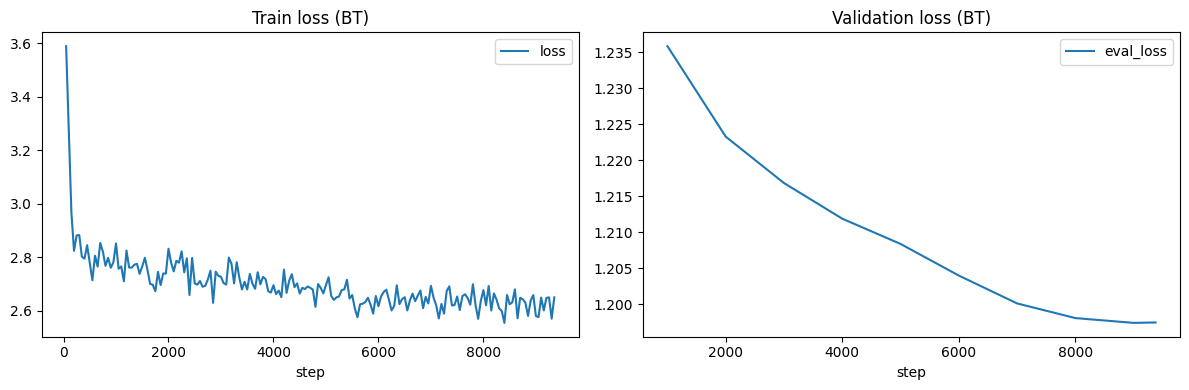

In [8]:
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUTPUT_DIR / "training_log.csv", index=False)
display(history.tail(15))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if "loss" in history:
    history.dropna(subset=["loss"]).plot(x="step", y="loss", ax=axes[0], title="Train loss (BT)")
if "eval_loss" in history:
    history.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=axes[1], title="Validation loss (BT)")
plt.tight_layout()
plt.show()

## 8. Évaluation BLEU / chrF du modèle BT (test held-out)

In [9]:
from sacrebleu import corpus_bleu, corpus_chrf

test_df = pd.read_csv(TEST_CSV)
model.eval()

def batched(values, size):
    for i in range(0, len(values), size):
        yield values[i:i + size]

def generate_for_group(group, batch_size=16):
    tokenizer.src_lang = group.iloc[0]["src_lang_nllb"]
    forced_bos_token_id = tokenizer.convert_tokens_to_ids(group.iloc[0]["tgt_lang_nllb"])
    predictions = []
    with torch.no_grad():
        for batch in batched(group["src_text"].tolist(), batch_size):
            enc = tokenizer(batch, return_tensors="pt", padding=True, truncation=True,
                            max_length=MAX_SOURCE_LENGTH).to(model.device)
            gen = model.generate(**enc, forced_bos_token_id=forced_bos_token_id,
                                 max_new_tokens=MAX_TARGET_LENGTH, num_beams=4)
            predictions.extend(tokenizer.batch_decode(gen, skip_special_tokens=True))
    return predictions

reports = []
all_eval = {}
for (sl, tl), group in test_df.groupby(["src_lang", "tgt_lang"], sort=True):
    group = group.sample(n=min(MAX_EVAL_PER_DIRECTION, len(group)), random_state=42).reset_index(drop=True)
    preds = generate_for_group(group, batch_size=16)
    refs = group["tgt_text"].tolist()
    all_eval[(sl, tl)] = {"pred": preds, "ref": refs}
    reports.append({"src_lang": sl, "tgt_lang": tl, "rows": len(group),
                    "bleu": round(float(corpus_bleu(preds, [refs]).score), 4),
                    "chrf": round(float(corpus_chrf(preds, [refs]).score), 4)})

report_df = pd.DataFrame(reports)
report_df.to_csv(OUTPUT_DIR / "evaluation_report.csv", index=False)
display(report_df)

,src_lang,tgt_lang,rows,bleu,chrf
0,eng,ewe,107,14.4484,32.0316
1,eng,fra,200,37.7995,63.0595
2,ewe,eng,111,18.5385,35.5671
3,ewe,fra,200,25.7774,44.5787
4,fra,eng,200,43.9132,63.8230
5,fra,ewe,200,23.6098,43.2851


## 9. Comparaison : modèle de base vs back-translation

Règle de décision : on **adopte** le modèle BT s'il **gagne sur en↔ewe sans régresser
ailleurs**. Sinon on garde le modèle de base (sauvegardé). La back-translation peut
dégrader si le synthétique est bruité — d'où cette comparaison systématique.

,direction,bleu_base,bleu_bt,d_bleu,chrf_base,chrf_bt,d_chrf
0,eng->ewe,13.8437,14.4484,0.60,32.0703,32.0316,-0.04
1,eng->fra,38.4676,37.7995,-0.67,63.3356,63.0595,-0.28
2,ewe->eng,18.3383,18.5385,0.20,34.8363,35.5671,0.73
3,ewe->fra,24.5343,25.7774,1.24,44.4147,44.5787,0.16
4,fra->eng,44.8420,43.9132,-0.93,65.0167,63.8230,-1.19
5,fra->ewe,22.6636,23.6098,0.95,43.1138,43.2851,0.17


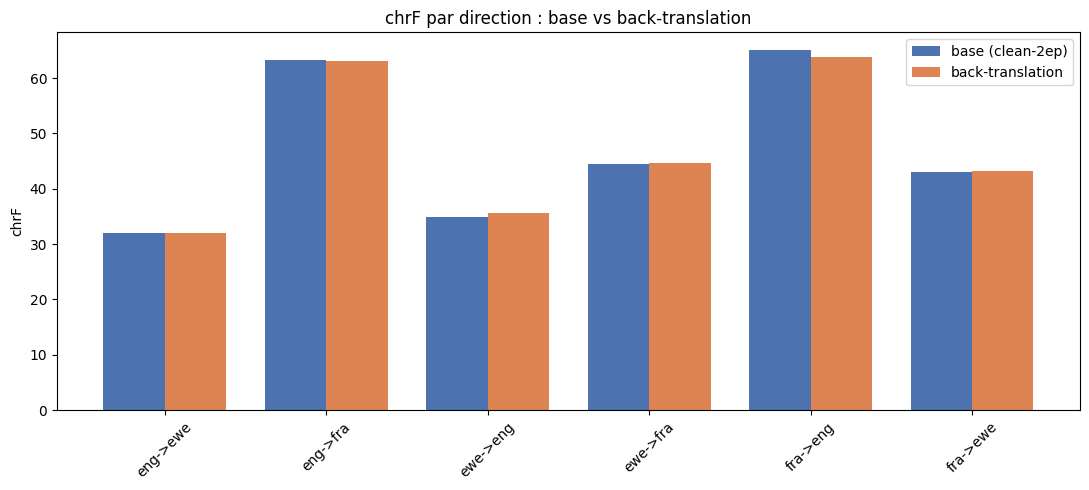

Gain moyen en<->ewe : d_chrf = 0.34 | d_bleu = 0.4
Variation moyenne autres directions : d_chrf = -0.29
=> Adopter le BT si gain en<->ewe > 0 ET pas de regression notable ailleurs.


In [10]:
import matplotlib.pyplot as plt
import numpy as np

base_report_path = BASELINE_DIR / "evaluation_report.csv"
if not base_report_path.exists():
    print("Rapport de base introuvable:", base_report_path)
    print("Lancez l'évaluation du modèle de base (notebook 01) ou copiez son evaluation_report.csv ici.")
else:
    base = pd.read_csv(base_report_path)[["src_lang", "tgt_lang", "bleu", "chrf"]]
    base = base.rename(columns={"bleu": "bleu_base", "chrf": "chrf_base"})
    bt = report_df[["src_lang", "tgt_lang", "bleu", "chrf"]].rename(
        columns={"bleu": "bleu_bt", "chrf": "chrf_bt"})
    cmp = base.merge(bt, on=["src_lang", "tgt_lang"])
    cmp["direction"] = cmp["src_lang"] + "->" + cmp["tgt_lang"]
    cmp["d_bleu"] = (cmp["bleu_bt"] - cmp["bleu_base"]).round(2)
    cmp["d_chrf"] = (cmp["chrf_bt"] - cmp["chrf_base"]).round(2)
    cmp = cmp.sort_values("direction").reset_index(drop=True)
    display(cmp[["direction", "bleu_base", "bleu_bt", "d_bleu", "chrf_base", "chrf_bt", "d_chrf"]])

    x = np.arange(len(cmp)); w = 0.38
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w / 2, cmp["chrf_base"], w, label="base (clean-2ep)", color="#4C72B0")
    ax.bar(x + w / 2, cmp["chrf_bt"], w, label="back-translation", color="#DD8452")
    ax.set_xticks(x); ax.set_xticklabels(cmp["direction"], rotation=45)
    ax.set_ylabel("chrF"); ax.set_title("chrF par direction : base vs back-translation")
    ax.legend(); plt.tight_layout(); plt.show()

    en_ewe = cmp[(cmp["src_lang"].isin(["eng", "ewe"])) & (cmp["tgt_lang"].isin(["eng", "ewe"]))]
    print("Gain moyen en<->ewe : d_chrf =", round(en_ewe["d_chrf"].mean(), 2),
          "| d_bleu =", round(en_ewe["d_bleu"].mean(), 2))
    autres = cmp[~cmp.index.isin(en_ewe.index)]
    print("Variation moyenne autres directions : d_chrf =", round(autres["d_chrf"].mean(), 2))
    print("=> Adopter le BT si gain en<->ewe > 0 ET pas de régression notable ailleurs.")